{'C': {'Rx': None, 'Ry': 0}}
{'C': {'Rx': None, 'Ry': 0}, 'D': {'Rx': 1, 'Ry': 2}}
[[ 0.  1.  0.]
 [ 1.  0.  1.]
 [ 0.  0. -1.]] [  0.  10. -15.]

Support Reactions

-----------------
C: Rx=+0.000, Ry=+5.000
D: Rx=-0.000, Ry=-15.000

Equilibrium Check

-----------------
ΣFx = +0.000
ΣFy = +0.000
ΣM  = -0.000 (about C)


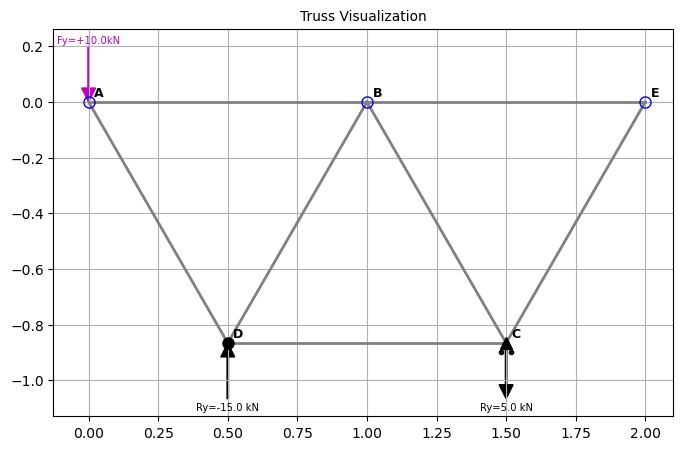

In [4]:
import numpy as np
from import_functions import extract_structure_from_dxf
import visualisation_functions as viz
from struct_prop_funcs import apply_joint_conditions
from struct_prop_funcs import calculate_total_forces
from structural_analysis import compute_support_reactions


INPUT_DXF = "example.dxf"
nodes, members = extract_structure_from_dxf(INPUT_DXF, units='mm', tol=0.1)


JOINT_CONDITIONS = {
"Pinned":            [],	     # Internal pin (free rotation, no support)	    ○	Blue
"Fixed":             [],         # Internal fixed joint (rigid)	                □	~Blue
"Reaction_Fixed":    [],	     # External fixed support	                    ■	Black
"Reaction_Pinned":   ['D'],      # External pinned support	                    ●	Black
"Reaction_Roller_H": ['C'],      # Horizontal roller (restrained vertically)	▲	Black
"Reaction_Roller_V": []	         # Vertical roller (restrained horizontally)	▼	Black
}

# assign joint conditions
apply_joint_conditions(nodes, JOINT_CONDITIONS)

P = 5
# Point load configuration
#nodes['C'].F_y = P # F_x is already zero
nodes['A'].F_y = 10

UDL = 2.5
wind = 6
# member loads
#members['A-B'].F_y = UDL # 2.5 kN/m down UDL on member AB
#members['B-E'].F_y = UDL # 2.5 kN/m down UDL on member AD
#members['C-E'].F_x = -wind # 2.5 kN/m down UDL on member AD

# Apply loads
calculate_total_forces(nodes, members) 

# compute reactions
reactions = compute_support_reactions(nodes, verbose=True)

# Visualize
fig = viz.visualize_truss(nodes, members, textscale=0.9, show_reactions=True, plot_loads=True, show_load_labels=True, show_node_labels=True,  show_force_labels=True)

In [41]:
import pandas as pd
pd.DataFrame(reactions)

,C,D
Rx,0.0,-0.0
Ry,-5.0,-5.0


### 7. Check Equilbrium

In [5]:
# Step 6: Detailed moment equilibrium check (debug)
print("\n ### Moment Equilibrium Breakdown (Clockwise Negative) ### ")
print(f"{'Label':<8} {'x':>8} {'y':>8} {'Fx':>10} {'Fy':>10} {'M = (xFy - yFx)':>18}")

# Applied loads (clockwise positive)
for lbl, n in nodes.items():
    Fx = n.F_xtotal or n.F_x #uses F_xtotal if it exists, F_x otherwise
    Fy = n.F_ytotal or n.F_y
    x, y = n.coords[:2]
    M = (x * Fy + y * Fx)  #  for clockwise negative
    print(f"{lbl:<8} {x:8.3f} {y:8.3f} {Fx:10.3f} {Fy:10.3f} {M:18.6f}")

# Supports and reactions
support_labels = [lbl for lbl in reactions.keys()]
support_nodes = {lbl: nodes[lbl] for lbl in support_labels}

print(" ### Reactions (Clockwise Negative) ### ")
for lbl, r in reactions.items():
    s = support_nodes[lbl]
    x, y = s.coords[:2]
    M = (x * r['Ry'] - y * r['Rx'])  # clockwise negative
    print(f"{lbl:<8} {x:8.3f} {y:8.3f} {r['Rx']:10.3f} {r['Ry']:10.3f} {M:18.6f}")

# Compute totals (clockwise negative)
M_total_loads = sum(
    n.coords[0] * (n.F_ytotal or n.F_y)
    - n.coords[1] * (n.F_xtotal or n.F_x)
    for n in nodes.values()
)
M_total_reac = sum(
    support_nodes[l].coords[0] * r['Ry']
    - support_nodes[l].coords[1] * r['Rx']
    for l, r in reactions.items()
)
M_check = M_total_loads + M_total_reac

print(f"\nM_total (loads, CW+) = {M_total_loads:.6f}")
print(f"M_reactions (CW+)   = {M_total_reac:.6f}")
print(f"ΣM (CW+) = {M_check:.6f}  (should be ≈ 0)\n")




 ### Moment Equilibrium Breakdown (Clockwise Negative) ### 
Label           x        y         Fx         Fy    M = (xFy - yFx)
A           0.000    0.000      0.000     10.000           0.000000
B           1.000    0.000      0.000      0.000           0.000000
C           1.500   -0.866      0.000      0.000           0.000000
D           0.500   -0.866      0.000      0.000           0.000000
E           2.000    0.000      0.000      0.000           0.000000
 ### Reactions (Clockwise Negative) ### 
C           1.500   -0.866      0.000      5.000           7.500000
D           0.500   -0.866     -0.000    -15.000          -7.500000

M_total (loads, CW+) = 0.000000
M_reactions (CW+)   = 0.000000
ΣM (CW+) = 0.000000  (should be ≈ 0)



### 8. Use method of joints to solve axial forces

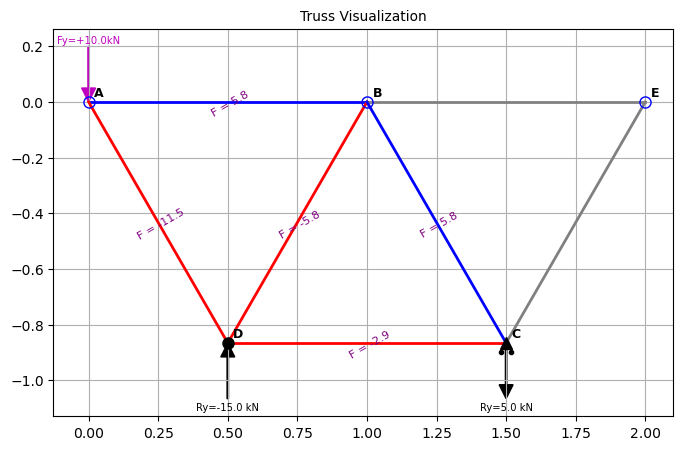

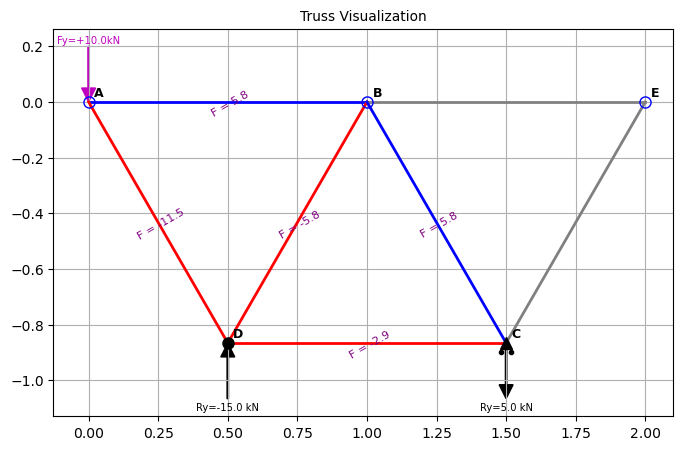

In [6]:
from structural_analysis import solve_truss_joint_iteration


# STRUCTURAL ANALYSIS
member_forces = solve_truss_joint_iteration(nodes, members)

# Visualize everything
viz.visualize_truss(nodes, members, textscale=0.9, show_reactions=True, plot_loads=True, show_node_labels=True, show_load_labels=True, show_forces=True, show_force_labels=True)

### 9. Compute and visualise member bending moments

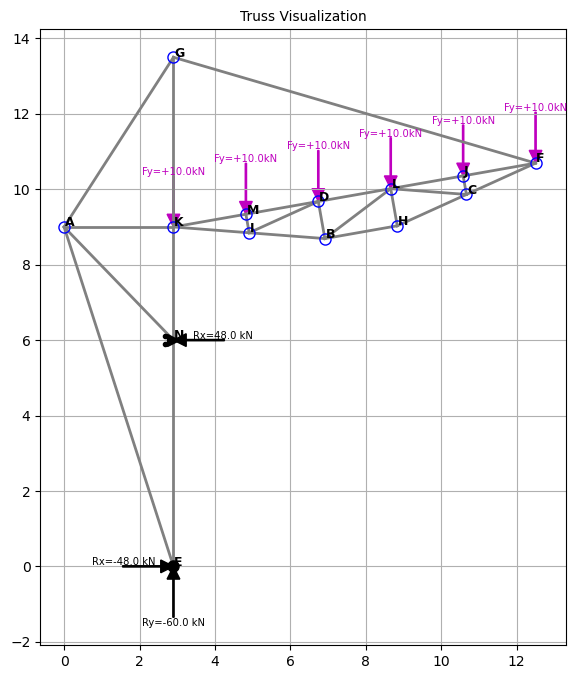

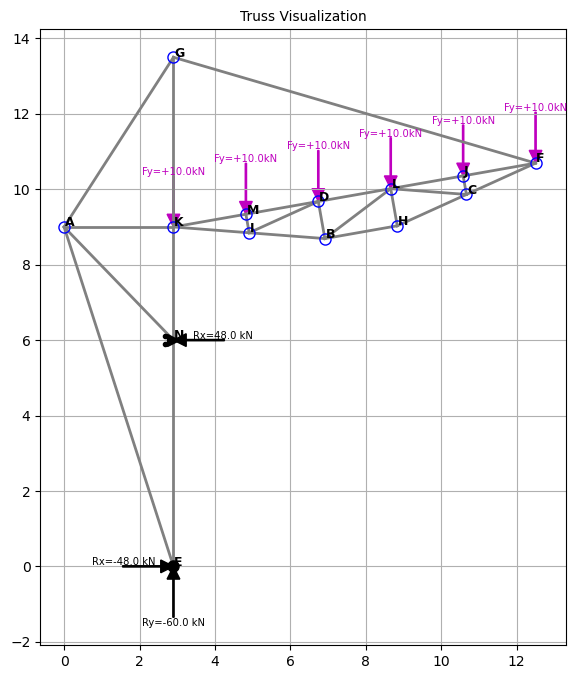

In [35]:
from structural_analysis import compute_member_bending_moments

member_moments = compute_member_bending_moments(members)

viz.visualize_truss(nodes, members, 
                    textscale=0.9, 
                    show_reactions=True, 
                    plot_loads=True, 
                    show_load_labels=True, 
                    show_node_labels=True,
                    show_bending_moments=True, 
                    show_bending_moment_labels=True, 
                    moment_scale=0.1)

In [17]:
members['B-E'].moments

{'M_start': 0.0,
 'M_end': 0.0,
 'M_max': 0.3125,
 'M_min': 0.0,
 'points': [np.float64(0.0),
  np.float64(0.062326869806094184),
  np.float64(0.11772853185595568),
  np.float64(0.16620498614958448),
  np.float64(0.2077562326869806),
  np.float64(0.24238227146814403),
  np.float64(0.2700831024930748),
  np.float64(0.29085872576177285),
  np.float64(0.3047091412742382),
  np.float64(0.31163434903047094),
  np.float64(0.3116343490304709),
  np.float64(0.3047091412742382),
  np.float64(0.2908587257617729),
  np.float64(0.2700831024930748),
  np.float64(0.2423822714681441),
  np.float64(0.20775623268698062),
  np.float64(0.16620498614958454),
  np.float64(0.11772853185595578),
  np.float64(0.06232686980609424),
  np.float64(0.0)],
 'Fx_udl': 0.0,
 'Fy_udl': 2.5}

## Next Steps... Do interesting things!

### 10. Calculates Stresses:

We need to account for the plus/minus effect:

σ total= σ axial ± σ bending

Tension axial stress + bending at the top fiber
Compression axial stress + bending at the top fiber


![](exercise_flow.png)

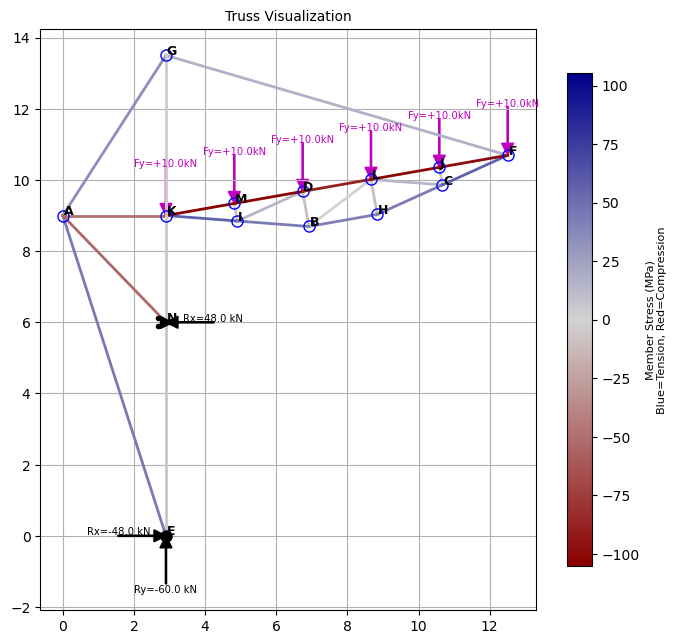

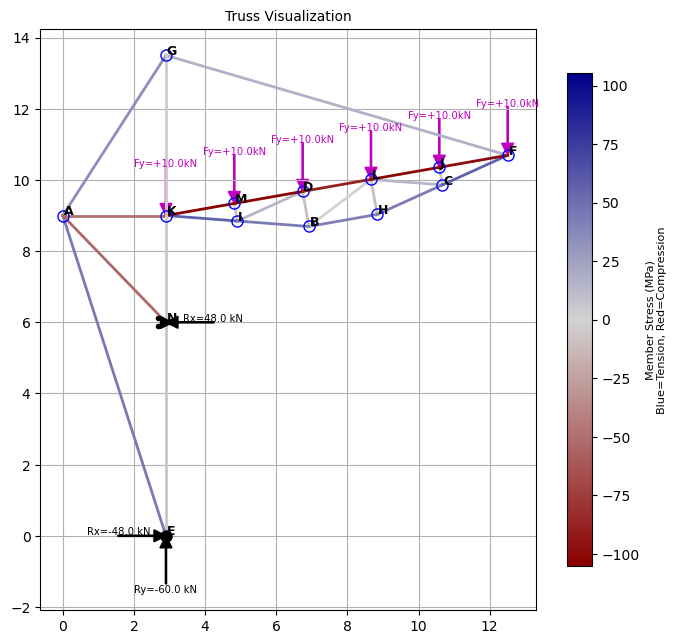

In [39]:
### Compute combined stresses (axial + bending) for all members.
### =======
### EXERCISE!!!
### ==========
#import numpy as np 

#def calculate_stresses(members):
    ###
    # YOUR CODE HERE
    ###
#    return max_stress, stresses
from ex_modans import calculate_stresses

max_stress,stresses = calculate_stresses(members)

viz.visualize_truss(nodes, members, textscale=0.9, show_reactions=True, plot_loads=True, show_node_labels=True, show_load_labels=True, show_stresses=True, show_colorbar=True )


In [40]:
m = members['A-B']
m.stress

KeyError: 'A-B'

### 11. Compute utilisation factors for members based on stress and material properties.


=== Utilisation Summary ===
Member       σ_total (MPa)     Allow (MPa)         Type     Utilisation
---------------------------------------------------------------------------
F-G                 16.549         355.000      Tension           0.047
A-K                -48.865         355.000  Compression           0.138
A-E                 44.725         500.000      Tension           0.089
A-G                 33.763         500.000      Tension           0.068
B-D                -10.704         355.000  Compression           0.030
B-H                 41.747         355.000      Tension           0.118
H-L                -10.704         355.000  Compression           0.030
C-J                 -7.136         355.000  Compression           0.020
I-M                 -7.136         355.000  Compression           0.020
D-I                 14.366         355.000      Tension           0.040
B-L                 -0.000         355.000  Compression           0.000
C-L                 14.366     

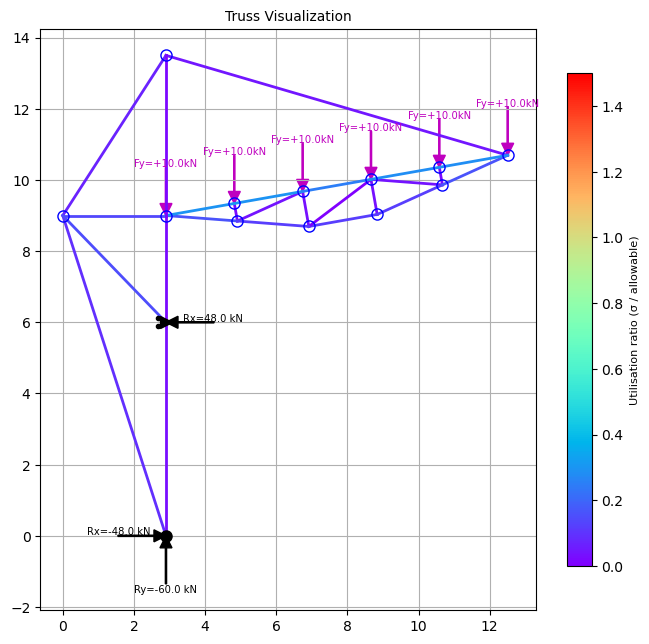

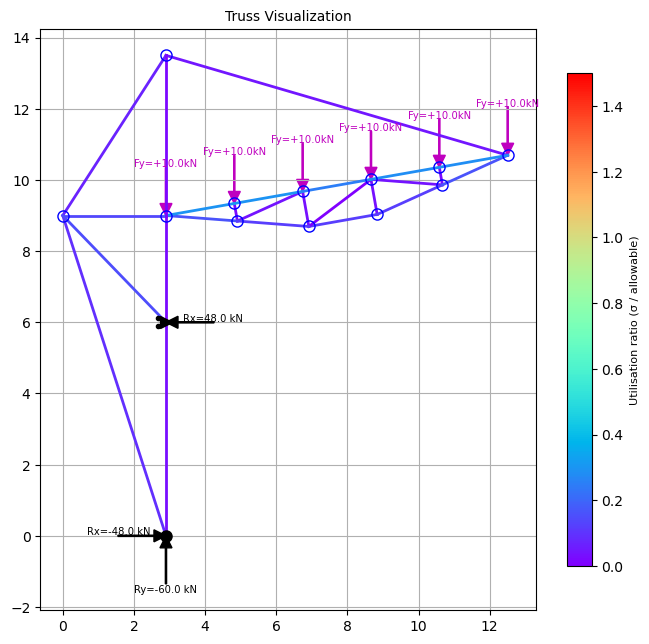

In [41]:
import math

def compute_utilisations(members):
    warn_limit=1.0
    utilisations = {}
    max_utilisation = 0.0
    overstressed = []
    
    # ANSI color helpers
    RED = "\033[91m"
    RESET = "\033[0m"
    
    print("\n=== Utilisation Summary ===")
    print(f"{'Member':<10} {'σ_total (MPa)':>15} {'Allow (MPa)':>15} {'Type':>12} {'Utilisation':>15}")
    print("-" * 75)
    
    for m in members.values():
        sigma = m.stress
        props = m.properties
    
        ft = props["ft"] 
        fc = props["fc"] 
    
        # Decide allowable stress based on sign
        if sigma >= 0:
            allowable = ft 
            stress_type = "Tension"
        else:
            allowable = fc 
            stress_type = "Compression"
    
        util = abs(sigma) / allowable
    
        utilisations[m.name] = util
        m.utilisation=util
        if not math.isinf(util):
            max_utilisation = max(max_utilisation, util)
    
        # Highlight overstressed members
        over = util > warn_limit
        allow_str = f"{allowable:.3f}" 
        util_str = f"{util:.3f}" 
    
        line = f"{m.name:<10} {sigma:15.3f} {allow_str:>15} {stress_type:>12} {util_str:>15}"
        if over:
            line = RED + line + RESET
            overstressed.append((m.name, util))
    
        print(line)
    
    print("-" * 75)
    print(f"Max utilisation = {max_utilisation:.3f}")
    
    if overstressed:
        print(f"\n!!!  Overstressed members (util > {warn_limit}):")
        for name, util in overstressed:
            print(f"  - {name}: {util:.3f}")
    else:
        print("\n=> All members within allowable limits.")
    return utilisations


utils1 = compute_utilisations(members)

viz.visualize_truss(nodes, members, textscale=0.9, show_reactions=True, plot_loads=True, show_load_labels=True, show_utilisations=True, show_colorbar=True )


## Making modifications to the structure

### 12. Run this to see and example of a structural change:

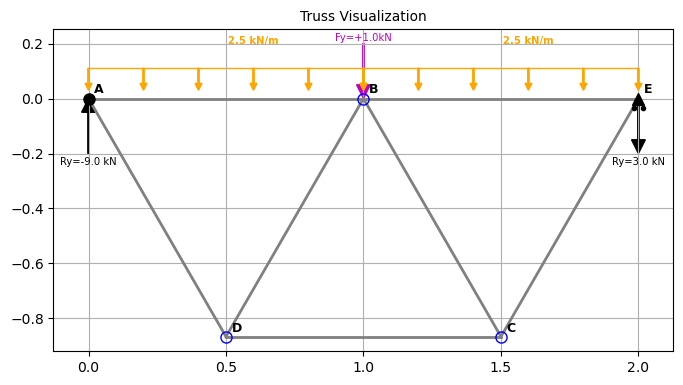

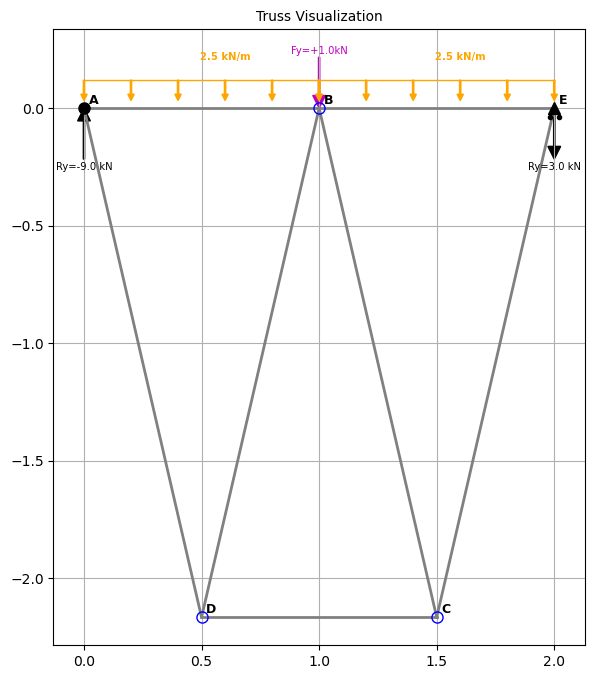

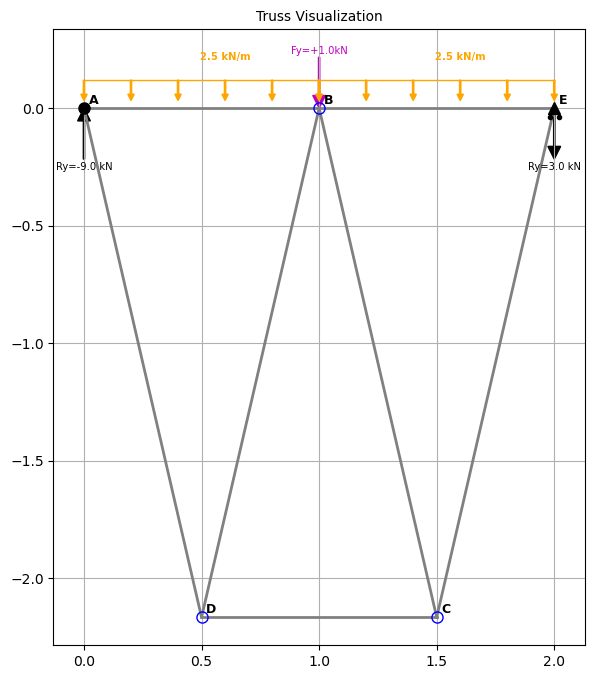

In [20]:
# Factor to stretch the structure
#WIDTH_SCALE = 2.5
HEIGHT_SCALE = 2.5

from copy import deepcopy
# deepcopy also makes a copy of all the objects within the dictionary
nodes2 = deepcopy(nodes)
members2 = deepcopy(members)
for m in members2.values():
    m.nodes=nodes2 

# scale and visualize
for n in nodes2.values():
    n.coords[1] *= HEIGHT_SCALE #same as: n.coords[1] = n.coords[1]*HEIGHT_SCALE

# Visualize
viz.visualize_truss(nodes, members, textscale=0.9, show_reactions=True, plot_loads=True, show_load_labels=True, show_node_labels=True)
viz.visualize_truss(nodes2, members2, textscale=0.9, show_reactions=True, plot_loads=True, show_load_labels=True, show_node_labels=True)

In [21]:
from computation_tools import compute_node_angles
from printing_tools import comparison_data

# Member lengths 
def member_lengths(members):
    lengths = {}
    for m in members.values():
        L = m.compute_length()
        lengths[m.name] = L
    return lengths


# Store original angles and lengths
original_lengths = member_lengths(members)
original_angles = compute_node_angles(nodes, members)


# calculate new angles and lengths
new_lengths = member_lengths(members2)
new_angles = compute_node_angles(nodes2, members2)

# Show the values as a table
df = comparison_data(original_angles, new_angles, original_lengths, new_lengths, print_output=False)

COMPARISON_SHEET_FILENAME = "compare_angles.xlsx"

# save data to excel
df.to_excel(COMPARISON_SHEET_FILENAME)
df

,Node,Member,Old Angle (°),New Angle (°),Old Length,New Length
Member Pair,,,,,,
A-B--A-D,A,A-B,60.0,76.996088,1.0,1.0
A-B--A-D,A,A-D,60.0,76.996088,1.0,2.222049
C-D--B-C,C,C-D,60.0,76.996088,1.0,1.0
C-D--C-E,C,C-D,120.0,103.003912,1.0,1.0
B-C--C-E,C,B-C,60.0,26.007824,1.0,2.222049
B-C--C-E,C,C-E,60.0,26.007824,1.0,2.222049
B-E--B-C,B,B-E,60.0,76.996088,1.0,1.0
B-D--B-C,B,B-D,60.0,26.007824,1.0,2.222049
A-D--B-D,D,A-D,60.0,26.007824,1.0,2.222049



--- Support Reactions ---
A: Rx=+0.000, Ry=-9.000
E: Rx=+0.000, Ry=+3.000

--- Equilibrium Check ---
ΣFx = +0.000
ΣFy = +0.000
ΣM  = +12.000 (about A)

=== Utilisation Summary ===
Member       σ_total (MPa)     Allow (MPa)         Type     Utilisation
---------------------------------------------------------------------------
A-B                 -2.054          14.000  Compression           0.147
B-E                  1.973           8.000      Tension           0.247
A-D                  0.998         355.000      Tension           0.003
B-D                 -0.998         355.000  Compression           0.003
C-D                  0.358           8.000      Tension           0.045
B-C                 -2.543         355.000  Compression           0.007
C-E                 -0.436          14.000  Compression           0.031
---------------------------------------------------------------------------
Max utilisation = 0.247

=> All members within allowable limits.


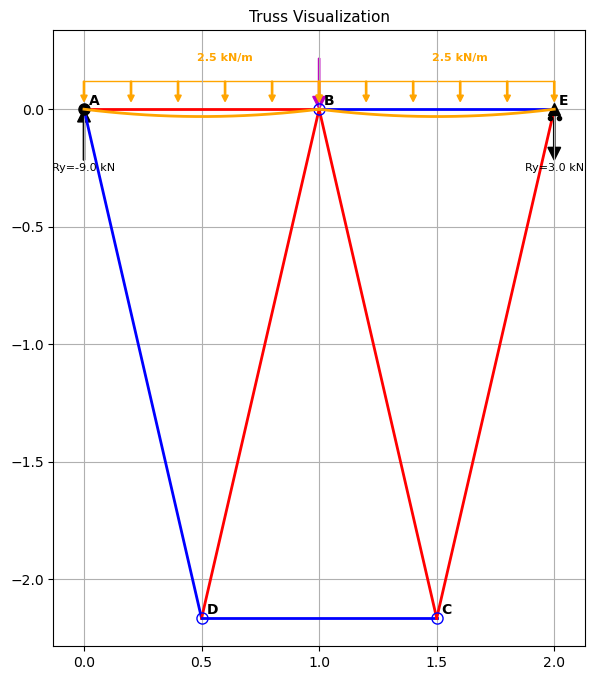

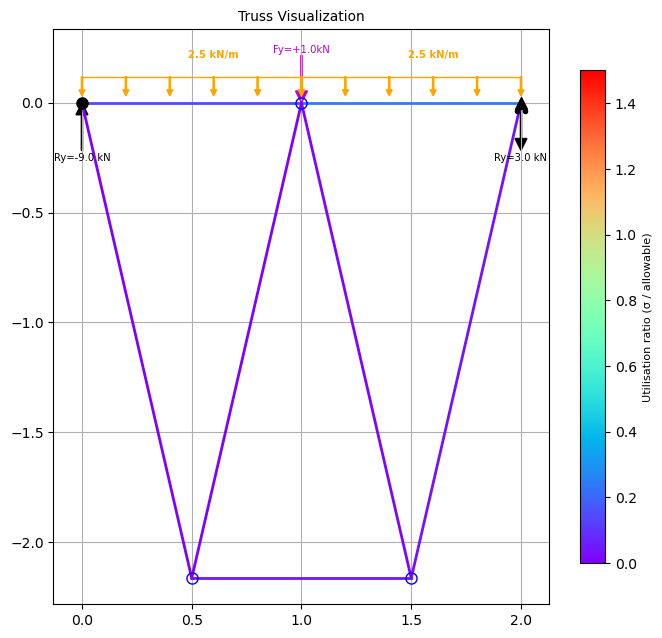

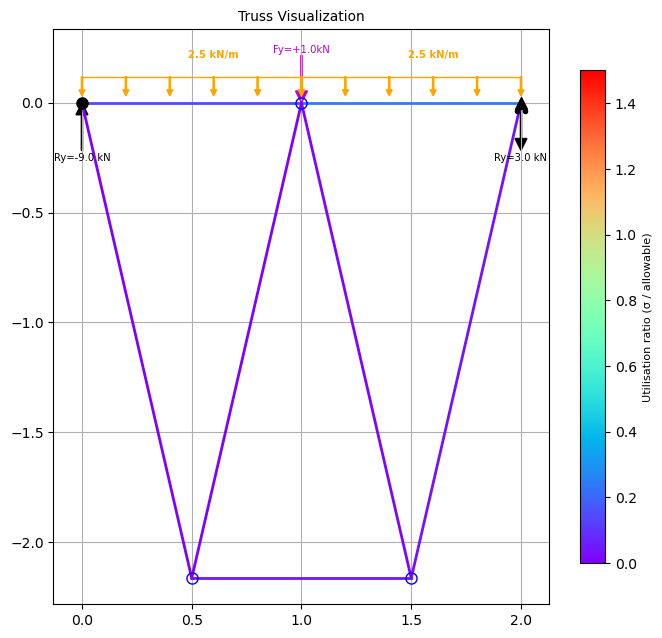

In [22]:
# STRUCTURAL RE-ANALYSIS

reactions2 = compute_support_reactions(nodes2, members2)
member_forces2 = solve_truss_joint_iteration(nodes2, members2)
member_moments2 = compute_member_bending_moments(members2)
max_stress2,stresses2 = calculate_stresses(members2)
utils2 = compute_utilisations(members2)

# Plot a figure of the new truss system
viz.visualize_truss(nodes2, members2, show_reactions=True, plot_loads=True, show_node_labels=True, show_forces=True, show_bending_moments=True, show_bending_moment_labels=False, moment_scale=0.1)
viz.visualize_truss(nodes2, members2, textscale=0.9, show_reactions=True, plot_loads=True, show_load_labels=True, show_utilisations=True, show_colorbar=True )


## 13. Finally: Save your new structure back to a DXF to import into AutoCAD

In [23]:
from import_functions import export_to_dxf

OUTPUT_DXF = "scaled_structure.dxf"

# save new structure
export_to_dxf(nodes, members, OUTPUT_DXF, units='mm')

=> DXF exported to scaled_structure.dxf
